In [2]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

In [5]:
%pip install otter-grader

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://packagemanager.posit.co/pypi/latest/simple
  Using cached https://p3m.dev/pypi/latest/packages/otter-grader/aad08cba3653b203c4bce5b2b40df675811ec13735207f2deda8d128120fd24a/otter_grader-7.0.0-py3-none-any.whl (145 kB)
  Using cached https://p3m.dev/pypi/latest/packages/dill/1e1ce33e978ae97fcfcff5638477032b801c46c7c65cf717f95fbc2248f79a9d/dill-0.4.1-py3-none-any.whl (120 kB)
  Using cached https://p3m.dev/pypi/latest/packages/fica/d5cb066cfdc67715f99efdbce2fdaeb0c92f67b5d2aaf0740397b984731de2d5/fica-0.4.1-py3-none-any.whl (13 kB)
  Using cached https://p3m.dev/pypi/latest/packages/ipylab/a24c29aeb7d6d8b26c150794ef30c8d9ac2e387c47ea49f9afd8fa19dcd07b62/ipylab-1.1.0-py3-none-any.whl (101 kB)
  Using cached https://p3m.dev/pypi/latest/packages/ipywidgets/f2b8cbcaae10252b809fbe4d7470db75c09b769a32cbf816d20e5ca6d3c5a79d/ipywidgets-8.1.9-py3-none-any.whl (140 kB)
  Using cached https://p3

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/AaronWanh/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [ ]:
# FINAL CODE
# import packages 
import matplotlib.pyplot as plt
import pandas as pd 

# Read salmon data into a variable
catch_data = pd.read_csv("data/salmon_data.csv")

# remove the column notesRegCode from dataframe
catch_data = catch_data.loc[: , ['Region', 'Year', 'Species', 'Catch']]

# update the row and change data type
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = '1'
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# calculate the average fish caught in each region in between 1878 and 1997 
avg_catch_year = catch_data.loc[(catch_data['Year'] >= 1878) & (catch_data['Year'] <= 1997), ['Region', 'Year', 'Species', 'Catch']]
avg_catch_year = avg_catch_year.groupby('Region')['Catch'].mean().nlargest(18)

# graph barplot 
avg_catch_year.plot(kind = 'bar')
plt.title('Average Fish Caught by Region between 1878 to 1997')
plt.xlabel('Region')
plt.ylabel('Average # of Fish Caught')


## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [3]:
# a.
import pandas as pd 

# Read salmon data into a variable
catch_data = pd.read_csv("data/salmon_data.csv")



<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [4]:
# b.
# first five rows of salmon dataset 
print(catch_data.head())

# white space
print()

# total unique values from each column 
print(catch_data.nunique())

  Region  Year notesRegCode  Species Catch
0    SSE  1886          NaN  Chinook     0
1    SSE  1887          NaN  Chinook     0
2    SSE  1888          NaN  Chinook     0
3    SSE  1889          NaN  Chinook     0
4    SSE  1890          NaN  Chinook     0

Region            18
Year             120
notesRegCode      29
Species            5
Catch           1879
dtype: int64


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

Having limited knowledge to this dataset, I used the head() function to observe the first 5 rows of the dataset along with the column names. Then using the nunique method, I wanted to observe how many different values are within each column. 

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [6]:
# print out all unique comments 

notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

<StringArray>
[                                                                                   nan,
                                                             'Includes Yakutat catches',
                                             'Yakutat catch included in No SE AK catch',
                                   'Estimated from canned production, probably sockeye',
                                                                           'No fishery',
                                'Bering River catches included in Copper River catches',
                                 'Includes Bering River catches; estimated from canned',
                                                        'Includes Bering River catches',
                                 'Coho and pink catch estimated from canned production',
                            'Includes Bering River; coho and pink estimated fro canned',
                                                     'Pink catch estimated from canned',
       

In [7]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [8]:
# remove the column notesRegCode from dataframe
catch_data = catch_data.loc[: , ['Region', 'Year', 'Species', 'Catch']]

In [9]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


_Type your answer here, replacing this text._

In [10]:
# show all columns data type 
 
catch_data.dtypes

Region       str
Year       int64
Species      str
Catch        str
dtype: object

While most of the columns have the expected the data type, the values for Catch seems to be integer values instead of a string. 

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [21]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [11]:
# locate the non integer string

catch_I = catch_data[catch_data['Catch'] == 'I']
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [12]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [13]:
# update the row
catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = '1'

# Store the updated row
catch_1 = catch_data.loc[catch_data['Catch'] == 'I', 'Catch'] = '1'

# print catch 1
catch_1

'1'

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [14]:
# change the data type of Catch to an integer 
catch_data['Catch'] = catch_data['Catch'].astype('int64')

catch_column_type = catch_data['Catch'].dtype
catch_column_type


dtype('int64')

In [15]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [16]:
# group region to find average fish caught in each region

avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [17]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

Text(0, 0.5, 'Average # of Fish Caught')

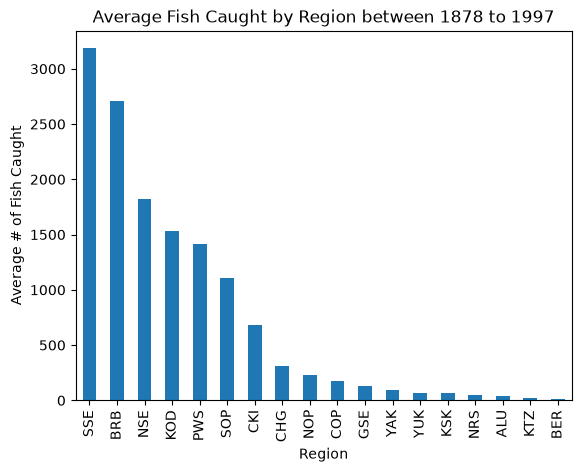

In [20]:
import matplotlib.pyplot as plt

# find the rows that are inbetween 1878 and 1997 
avg_catch_year = catch_data.loc[(catch_data['Year'] >= 1878) & (catch_data['Year'] <= 1997), ['Region', 'Year', 'Species', 'Catch']]

# calculate the average fish caught in each region in descending order
avg_catch_year = avg_catch_year.groupby('Region')['Catch'].mean().nlargest(18)

# graph barplot 
avg_catch_year.plot(kind = 'bar')
plt.title('Average Fish Caught by Region between 1878 to 1997')
plt.xlabel('Region')
plt.ylabel('Average # of Fish Caught')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

Based on our graph, we can see that Bristol Bay and Southern Southeast Alaska had the highest fish caught while Northern Southeast Alaska, Kodiak, Prince William Sound Subarea, and South Peninsula Subarea covered the mid-range for average fish caught. The other regions had a relatively minimal average compared to the top 6 regions in Alaska. 

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [21]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!